# Описание датасета Iris Flower

**Предметная область:** Ботаника, классификация растений. Исследование морфологических различий между видами ирисов.

**Источник:** [Iris Flower Dataset](https://www.kaggle.com/datasets/arshid/iris-flower-dataset) (Kaggle, оригинал — UCI Machine Learning Repository).

**Тип данных:** Реальные данные. 150 образцов ирисов, собранных Эдгаром Андерсоном в Гаспе.

**Набор применим для:**
- **Классификация:** определение вида ириса по измерениям его частей.
- **Кластеризация:** разбиение цветков на группы по морфологическим признакам.
- **Регрессия:** прогнозирование размера лепестка на основе других измерений.

**Признаки:**

| Признак | Тип | Описание |
| :--- | :--- | :--- |
| sepal_length | Числовой | Длина чашелистика, см |
| sepal_width | Числовой | Ширина чашелистика, см |
| petal_length | Числовой | Длина лепестка, см |
| petal_width | Числовой | Ширина лепестка, см |
| species | Категориальный | Вид ириса: Setosa, Versicolor, Virginica |

Для датасета Iris были добавлены два новых признака:
- `petal_area` = petal_length × petal_width — площадь лепестка.
- `sepal_area` = sepal_length × sepal_width — площадь чашелистика.
  
**Целевой класс: species (вид ириса: Setosa, Versicolor, Virginica).**

**Сбалансированность классов: по 50 записей каждого вида — датасет сбалансирован.**

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, auc, classification_report,
                             confusion_matrix)

In [18]:
df = pd.read_csv('datasets/IRIS.csv')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [19]:
df['species'].value_counts()


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [20]:
df['petal_area'] = df['petal_length'] * df['petal_width']
df['sepal_area'] = df['sepal_length'] * df['sepal_width']

In [21]:
print("Дубликатов:", df.duplicated().sum())
df = df.drop_duplicates()

Дубликатов: 3


In [22]:
print("Пропусков:", df.isnull().sum().sum())


Пропусков: 0


In [23]:
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
            'petal_area', 'sepal_area']
X = df[features]
y = df['species']

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [25]:
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (102, 6) Test: (45, 6)


In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

print("=== kNN ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_knn):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_knn, average='weighted'):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_knn, average='weighted'):.3f}")
print(f"F1:        {f1_score(y_test, y_pred_knn, average='weighted'):.3f}")
print()
print(classification_report(y_test, y_pred_knn))

=== kNN ===
Accuracy:  0.956
Precision: 0.961
Recall:    0.956
F1:        0.955

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.88      1.00      0.94        15
 Iris-virginica       1.00      0.87      0.93        15

       accuracy                           0.96        45
      macro avg       0.96      0.96      0.96        45
   weighted avg       0.96      0.96      0.96        45



In [28]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

print("=== Decision Tree ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tree):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_tree, average='weighted'):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_tree, average='weighted'):.3f}")
print(f"F1:        {f1_score(y_test, y_pred_tree, average='weighted'):.3f}")
print()
print(classification_report(y_test, y_pred_tree))

=== Decision Tree ===
Accuracy:  0.911
Precision: 0.930
Recall:    0.911
F1:        0.910

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.79      1.00      0.88        15
 Iris-virginica       1.00      0.73      0.85        15

       accuracy                           0.91        45
      macro avg       0.93      0.91      0.91        45
   weighted avg       0.93      0.91      0.91        45



1. **kNN показал более высокую точность** (Accuracy = 0.956) 
   по сравнению с деревом решений (Accuracy = 0.911).

2. **Причина:** kNN использует расстояния между объектами 
   и голосование ближайших соседей. Для Iris, где группы 
   компактны и хорошо разделены, это работает отлично.

3. **Дерево решений с max_depth=3** ограничено в глубине. 
   Оно разделяет пространство на прямоугольники, и на границе 
   между Versicolor и Virginica ошибается чаще:
   - 4 объекта Virginica ошибочно отнесены к Versicolor.

4. **Setosa классифицируется идеально** обоими алгоритмами — 
   этот класс линейно отделим от двух других.

5. **Versicolor и Virginica частично пересекаются** — именно 
   на этих классах возникают ошибки.

6. **Вывод:** для Iris kNN показал себя лучше, но дерево решений 
   более интерпретируемо — можно посмотреть, какие признаки 
   используются для разделения.

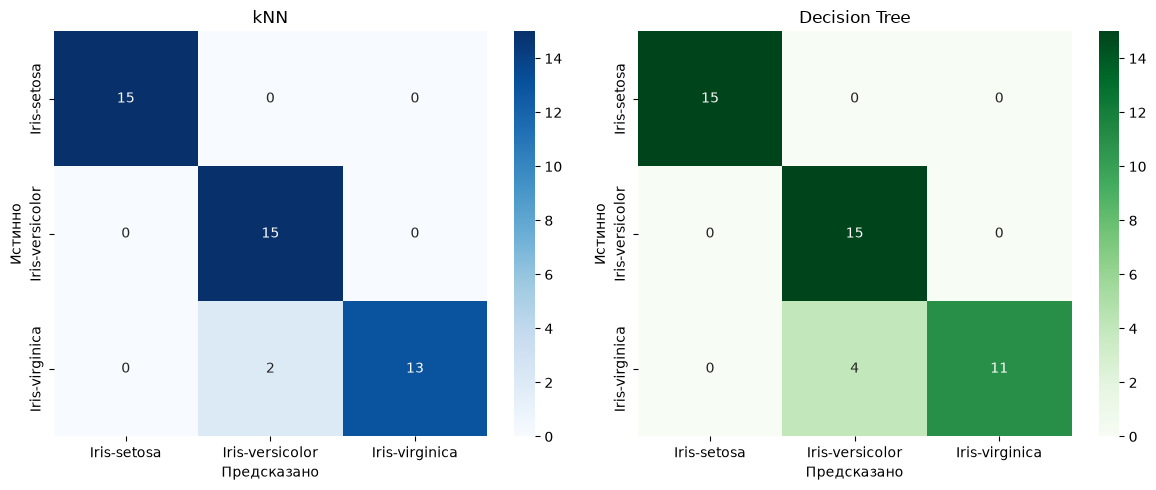

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# kNN
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=knn.classes_, yticklabels=knn.classes_)
axes[0].set_title('kNN')
axes[0].set_xlabel('Предсказано')
axes[0].set_ylabel('Истинно')

# Decision Tree
cm_tree = confusion_matrix(y_test, y_pred_tree)
sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=tree.classes_, yticklabels=tree.classes_)
axes[1].set_title('Decision Tree')
axes[1].set_xlabel('Предсказано')
axes[1].set_ylabel('Истинно')

plt.tight_layout()
plt.show()

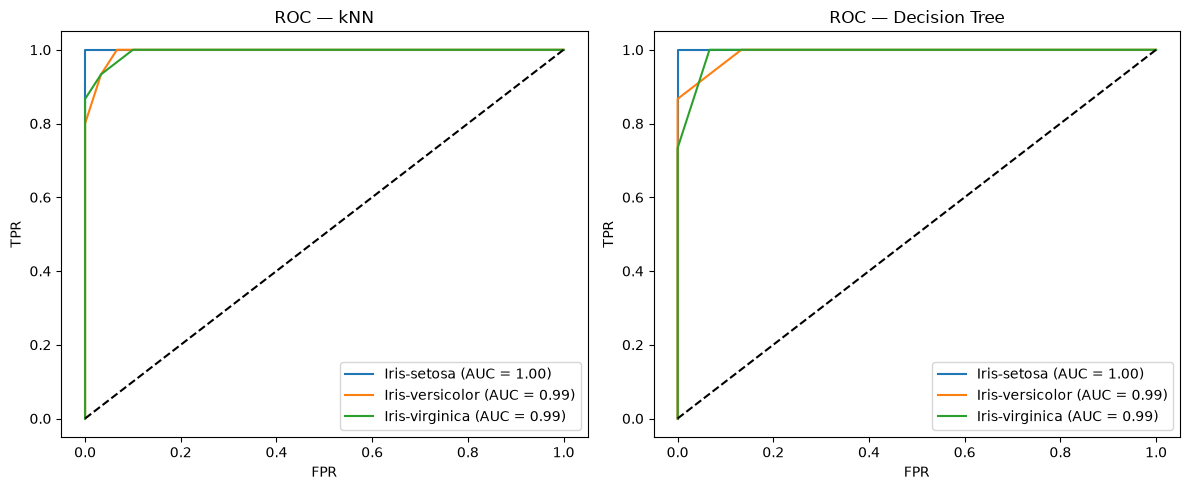

In [31]:
y_test_bin = label_binarize(y_test, classes=['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'])
n_classes = y_test_bin.shape[1]

y_score_knn = knn.predict_proba(X_test_scaled)
y_score_tree = tree.predict_proba(X_test)

# ROC для kNN
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score_knn[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{knn.classes_[i]} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC — kNN')
plt.legend()

# ROC для дерева
plt.subplot(1, 2, 2)
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score_tree[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{tree.classes_[i]} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC — Decision Tree')
plt.legend()

plt.tight_layout()
plt.show()

**ROC-кривые (One-vs-Rest):**

Для многоклассовой задачи ROC-кривые построены для каждого класса 
отдельно (One-vs-Rest). Результаты:

| Класс | kNN (AUC) | Decision Tree (AUC) |
| :--- | :--- | :--- |
| Setosa | 1.00 | 1.00 |
| Versicolor | 0.99 | 0.99 |
| Virginica | 0.99 | 0.99 |

**Анализ:**
- Все кривые близки к левому верхнему углу — модели отлично разделяют классы.
- Setosa классифицируется идеально (AUC = 1.00) обоими алгоритмами.
- Versicolor и Virginica показывают AUC = 0.99 — почти идеально, 
  что отражает их частичное пересечение.
- Разница между kNN и деревом решений минимальна.

**Вывод:** оба алгоритма показывают отличное качество классификации 
по метрике ROC-AUC (> 0.99 для всех классов).